In [2]:
import scanpy as sc
import matplotlib as mpl
import pandas as pd
import matplotlib.pyplot as plt
import os
import palantir
import gc
import numpy as np
import scvi
import scipy

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = "Arial"
sc._settings.settings._vector_friendly=True

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
Global seed set to 0
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import torch
torch.set_float32_matmul_precision("high")
torch.cuda.is_available()

True

In [ ]:
# Variables
batch_key = "sampleID"
run_date = '240308'
n_hgv = '5000'
min_cells_per_sample = 100

# Load data

In [4]:
under_20 = sc.read("/data1/trajectory_JL/step_1_subsetted_data/neuron_under_20.h5ad")
under_20.X = under_20.layers['counts'].copy()

In [5]:
under_20.obs['Dataset'] = under_20.obs['Dataset'].astype('category')
under_20.obs['Assay'] = under_20.obs['Assay'].astype('category')
under_20.obs['Library'] = under_20.obs['Library'].astype('category')
under_20.obs['batch'] = under_20.obs['batch'].astype('category')
under_20

AnnData object with n_obs × n_vars = 157447 × 49133
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

In [6]:
samples_to_exclude = []
for sample in under_20.obs["sampleID"].unique():
    if under_20[under_20.obs["sampleID"] == sample].X.shape[0] <= min_cells_per_sample :
        samples_to_exclude.append(sample)

print(samples_to_exclude)
print(len(samples_to_exclude))

[]
0


In [7]:
print(len(under_20.obs["sampleID"].unique()))
under_20_use = under_20[~under_20.obs["sampleID"].isin(samples_to_exclude)]
print(len(under_20_use.obs["sampleID"].unique()))

76
76


In [8]:
under_20_use

View of AnnData object with n_obs × n_vars = 157447 × 49133
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

# Preprocessing

In [9]:
sc.pp.normalize_total(under_20_use)
sc.pp.log1p(under_20_use)
under_20_use.layers["logcounts"] = under_20_use.X.copy()

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:169: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [10]:
#under_20_use.X = scipy.sparse.csr_matrix(under_20_use.X)

#under_20_use.var_names_make_unique()
sc.pp.highly_variable_genes(
    under_20_use, n_top_genes=int(n_hgv), flavor="cell_ranger", batch_key=batch_key
)

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated an

# Run SCVI & UMAP

In [11]:
scvi.settings.seed = 0

Global seed set to 0


In [12]:
under_20_scvi = under_20_use[:, under_20_use.var["highly_variable"]].copy()
under_20_scvi

AnnData object with n_obs × n_vars = 157447 × 5000
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon', 'hvg'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

In [13]:
scvi.model.SCVI.setup_anndata(under_20_scvi, 
                              layer="counts", 
                              batch_key=batch_key, 
                              categorical_covariate_keys=["Dataset", "Assay", "Library"])
under_20_scvi

AnnData object with n_obs × n_vars = 157447 × 5000
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon', 'hvg', '_scvi_uuid', '_scvi_manager_uuid'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

In [14]:
model_scvi = scvi.model.SCVI(under_20_scvi)
model_scvi.train() 

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2]


Epoch 51/51: 100%|██████████| 51/51 [11:51<00:00, 13.60s/it, loss=2.59e+03, v_num=1]

`Trainer.fit` stopped: `max_epochs=51` reached.


Epoch 51/51: 100%|██████████| 51/51 [11:51<00:00, 13.94s/it, loss=2.59e+03, v_num=1]


In [15]:
under_20_use.obsm["X_scVI_sampleID"] = model_scvi.get_latent_representation()

In [16]:
sc.pp.neighbors(under_20_use, use_rep="X_scVI_sampleID")

In [17]:
sc.tl.umap(under_20_use)

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


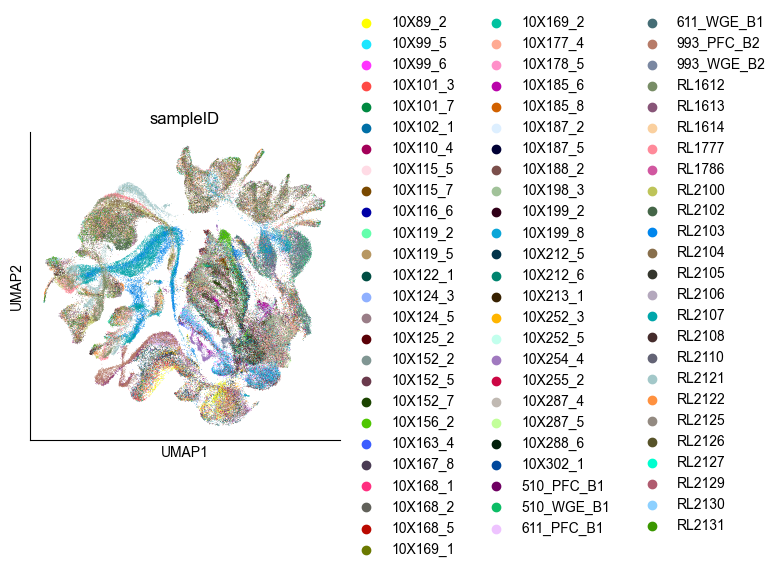

In [18]:
sc.pl.umap(under_20_use, color = "sampleID")

In [19]:
under_20_use.write_h5ad('/data1/trajectory_JL/step_2_scvi_result_data/under_20_scvi_240322.h5ad')

# Palantir

In [5]:
under_20_use = sc.read_h5ad('/data1/trajectory_JL/step_2_scvi_result_data/under_20_scvi_240322.h5ad')

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


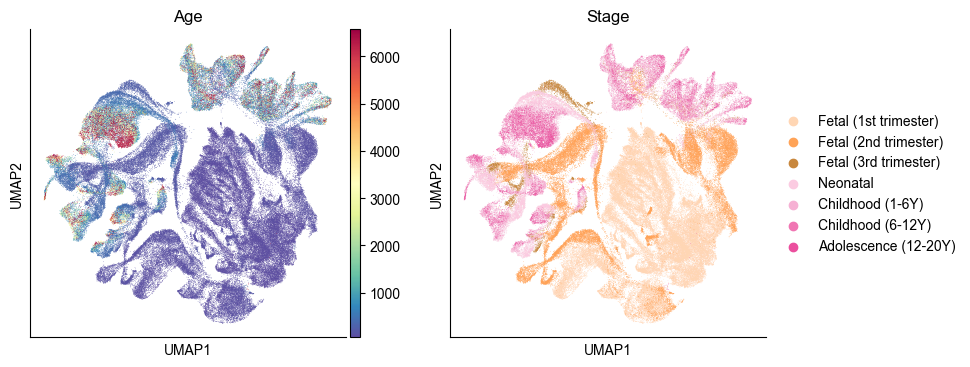

In [45]:
sc.pl.umap(under_20_use, color = ["Age", "Stage"])

## 1. diffusion components, impute X

In [7]:
dm_res = palantir.utils.run_diffusion_maps(under_20_use, pca_key = "X_scVI_sampleID") 
ms_data = palantir.utils.determine_multiscale_space(under_20_use)

In [8]:
imputed_X = palantir.utils.run_magic_imputation(under_20_use)

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9

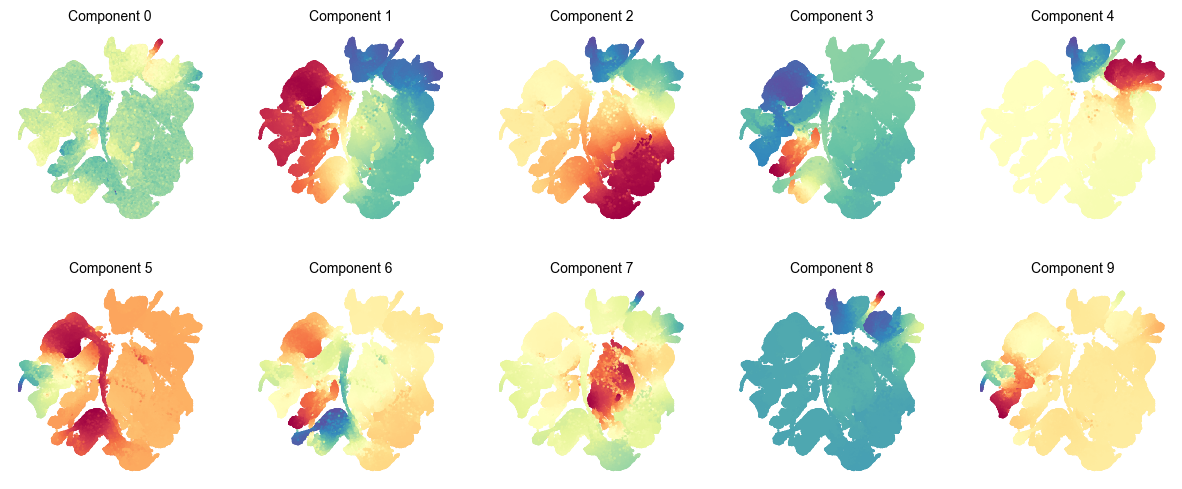

In [9]:
palantir.plot.plot_diffusion_components(under_20_use)
plt.show()

## 2. run pseudotime

2-1 start cell 

In [10]:
min_age = min(under_20_use[under_20_use.obs["Cell Type"] == "RG"].obs['Age'])

In [12]:
start_cell = under_20_use.obs.loc[(under_20_use.obs['Cell Type'] == "RG"), :].query('Age == Age.min()').index[0]

In [13]:
start_cell 
# '10X178_5:ATCATTCAGCATCGAG'

'10X178_5:ATCATTCAGCATCGAG'

In [14]:
under_20_use.uns['start_cell']=start_cell

10X178_5:ATCATTCAGCATCGAG


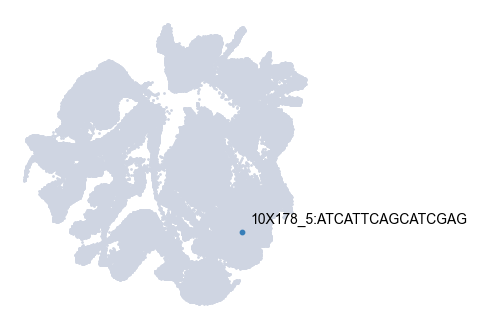

In [15]:


print(start_cell)
start_cell_spot = pd.Series(
    [start_cell],
    index=[start_cell],
)
palantir.plot.highlight_cells_on_umap(under_20_use, start_cell_spot)
plt.show()

In [ ]:
# under_20_use.uns['start_cell'] = 

2-2 run pseudotime and save

In [16]:
pr_res = palantir.core.run_palantir(
    under_20_use, start_cell)

Sampling and flocking waypoints...
Time for determining waypoints: 0.9219240705172221 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...


/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9

Time for shortest paths: 8.213970406850178 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


In [17]:
under_20_use.write_h5ad('/data1/trajectory_JL/step_3_pseudotime_result_data/under_20_pseudotime_240322.h5ad')

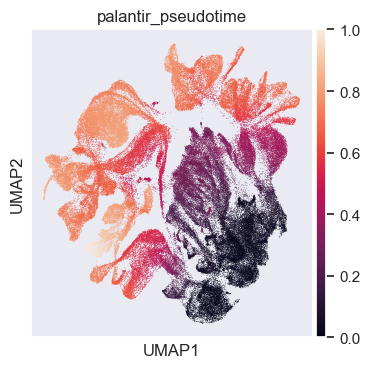

In [97]:
sc.pl.umap(under_20_use, color = "palantir_pseudotime")
plt.savefig("/data1/trajectory_JL/figures/under_20_pseudotime_2240323.pdf")
plt.show()

## 3. Data for plotting

3-2 Name lineages

In [19]:
masks = palantir.presults.select_branch_cells(under_20_use)

In [20]:
under_20_use.obsm['branch_masks']

,RL2106_ATTTCACCAGACACCC-1,RL2108_GTCCTCAAGAATCCCT-1,RL2125_AATGGAAAGGAAGAAC-1
10X119_2:TCGTACCCAGACAAAT,True,True,True
10X119_2:AGAGCGACACCGCTAG,True,True,True
10X119_2:AAGGAGCGTTGAGTTC,False,False,False
10X119_2:ATAGACCAGGGTGTTG,True,True,True
10X119_2:TTAGGCATCCGAACGC,True,True,True
...,...,...,...
RL2131_TTTCGATTCCAAGCAT-1,False,True,False
RL2131_TTTGATCCAACATCGT-1,False,True,False
RL2131_TTTGGAGGTGCAATGG-1,False,False,False
RL2131_TTTGGTTTCACGATAC-1,False,False,False


In [ ]:
under_20_use.obsm['branch_masks'] = under_20_use.obsm['branch_masks'].rename(columns = {'RL2106_ATTTCACCAGACACCC-1': 'Lineage_2',
                                                   'RL2108_GTCCTCAAGAATCCCT-1': 'Lineage_1',
                                                   'RL2125_AATGGAAAGGAAGAAC-1': 'Lineage_3'}).copy()

under_20_use.obsm['palantir_fate_probabilities'] = under_20_use.obsm['palantir_fate_probabilities'].rename(columns = {'RL2106_ATTTCACCAGACACCC-1': 'Lineage_2',
                                                   'RL2108_GTCCTCAAGAATCCCT-1': 'Lineage_1',
                                                   'RL2125_AATGGAAAGGAAGAAC-1': 'Lineage_3'}).copy()

In [33]:
under_20_use.layers['MAGIC_imputed_data'] = imputed_X

3-2 Gene trends for plotting

In [ ]:
gene_trends = palantir.presults.compute_gene_trends(
    under_20_use,
    expression_key="MAGIC_imputed_data",
)

# Wilcoxon ranksum test for each lineage

In [38]:
under_20_use.obs["Lineage_1"] = under_20_use.obsm['branch_masks']["Lineage_1"]
under_20_use.obs['Lineage_1'] = under_20_use.obs['Lineage_1'].astype('category')

under_20_use.obs["Lineage_2"] = under_20_use.obsm['branch_masks']["Lineage_2"]
under_20_use.obs['Lineage_2'] = under_20_use.obs['Lineage_2'].astype('category')

under_20_use.obs["Lineage_3"] = under_20_use.obsm['branch_masks']["Lineage_3"]
under_20_use.obs['Lineage_3'] = under_20_use.obs['Lineage_3'].astype('category')

In [46]:
sc.tl.rank_genes_groups(under_20_use, groupby = "Lineage_1", method='wilcoxon', key_added = "lineage_1_wilcoxon", pts = True, pts_rest = True)

result = under_20_use.uns['lineage_1_wilcoxon']
groups = result['names'].dtype.names

df_1 = pd.DataFrame(
{group + '_' + key: result[key][group]
for group in groups for key in ['names','scores','logfoldchanges', 'pvals','pvals_adj', 'pts', 'pts_rest']})
df_1.to_csv('/data1/trajectory_JL/tables/under_20_lineage_1_wilcoxon_result.csv')

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [47]:
sc.tl.rank_genes_groups(under_20_use, groupby = "Lineage_2", method='wilcoxon', key_added = "lineage_2_wilcoxon", pts = True, pts_rest = True)

result = under_20_use.uns['lineage_2_wilcoxon']
groups = result['names'].dtype.names

df_2 = pd.DataFrame(
{group + '_' + key: result[key][group]
for group in groups for key in ['names','scores','logfoldchanges', 'pvals','pvals_adj', 'pts', 'pts_rest']})
df_2.to_csv('/data1/trajectory_JL/tables/under_20_lineage_2_wilcoxon_result.csv')

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [48]:
sc.tl.rank_genes_groups(under_20_use, groupby = "Lineage_3", method='wilcoxon', key_added = "lineage_3_wilcoxon", pts = True, pts_rest = True)

result = under_20_use.uns['lineage_3_wilcoxon']
groups = result['names'].dtype.names

df_3 = pd.DataFrame(
{group + '_' + key: result[key][group]
for group in groups for key in ['names','scores','logfoldchanges', 'pvals','pvals_adj', 'pts', 'pts_rest']})
df_3.to_csv('/data1/trajectory_JL/tables/under_20_lineage_3_wilcoxon_result.csv')

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [49]:
with pd.ExcelWriter('/data1/trajectory_JL/tables/under_20_wilcoxon_result_all.xlsx') as excel_writer:
    df_1.to_excel(excel_writer, sheet_name='Lineage_1', index=False)
    df_2.to_excel(excel_writer, sheet_name='Lineage_2', index=False)
    df_3.to_excel(excel_writer, sheet_name='Lineage_3', index=False)

In [ ]:
genes = []
palantir.plot.plot_gene_trends(under_20_use, genes)

# Wilcoxon ranksum test within Lineage_1

In [ ]:
lineage_1_cells = under_20_use[under_20_use.obs["Lineage_1"] == True]
lineage_1_cells.obs["Lineage_1"]

In [ ]:
lineage_1_cells = lineage_1_cells[lineage_1_cells.obs.palantir_pseudotime.sort_values().index, :]
n_cells_top_bottom = int(0.33 * lineage_1_cells.n_obs)

top_33_percent_indices = lineage_1_cells.obs_names.tolist()[-n_cells_top_bottom:]
bottom_33_percent_indices = lineage_1_cells.obs_names.tolist()[:n_cells_top_bottom]

# Create a new column 'top_33_pseudotime' and assign True/False
lineage_1_cells.obs['top_33_pseudotime'] = [obs_name in top_33_percent_indices for obs_name in lineage_1_cells.obs_names]

# Create a new column 'bottom_33_pseudotime' and assign True/False
lineage_1_cells.obs['bottom_33_pseudotime'] = [obs_name in bottom_33_percent_indices for obs_name in lineage_1_cells.obs_names]

lineage_1_cells.obs['middle_33_pseudotime'] = ~(
    lineage_1_cells.obs['top_33_pseudotime'] | lineage_1_cells.obs['bottom_33_pseudotime']
)

In [ ]:
lineage_1_cells.obs['top_33_pseudotime'] = lineage_1_cells.obs['top_33_pseudotime'].astype('category')
lineage_1_cells.obs['middle_33_pseudotime'] = lineage_1_cells.obs['middle_33_pseudotime'].astype('category')
lineage_1_cells.obs['bottom_33_pseudotime'] = lineage_1_cells.obs['bottom_33_pseudotime'].astype('category')

In [ ]:
lineage_1_cells.obs[['top_33_pseudotime', 'bottom_33_pseudotime', 'palantir_pseudotime']]

In [ ]:
sc.tl.rank_genes_groups(lineage_1_cells, groupby = "top_33_pseudotime", method='wilcoxon', key_added = "top_33_wilcoxon", pts = True, pts_rest = True)


/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [ ]:

result =(lineage_1_cells).uns['top_33_wilcoxon']
groups = result['names'].dtype.names

df_top = pd.DataFrame(
{group + '_' + key: result[key][group]
for group in groups for key in ['names','scores','logfoldchanges', 'pvals','pvals_adj', 'pts', 'pts_rest']})
df_top.to_csv('/data1/trajectory_JL/tables/under_20_lineage_1_top_33_wilcoxon_result.csv')

In [ ]:
sc.tl.rank_genes_groups(lineage_1_cells, groupby = "middle_33_pseudotime", method='wilcoxon', key_added = "middle_33_wilcoxon", pts = True, pts_rest = True)



/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [ ]:

result =(lineage_1_cells).uns['middle_33_wilcoxon']
groups = result['names'].dtype.names

df_middle = pd.DataFrame(
{group + '_' + key: result[key][group]
for group in groups for key in ['names','scores','logfoldchanges', 'pvals','pvals_adj', 'pts', 'pts_rest']})
df_middle.to_csv('/data1/trajectory_JL/tables/under_20_lineage_1_middle_33_wilcoxon_result.csv')

In [ ]:
sc.tl.rank_genes_groups(lineage_1_cells, groupby = "bottom_33_pseudotime", method='wilcoxon', key_added = "bottom_33_wilcoxon", pts = True, pts_rest = True)


/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [ ]:
result =(lineage_1_cells).uns['bottom_33_wilcoxon']
groups = result['names'].dtype.names

df_bottom = pd.DataFrame(
{group + '_' + key: result[key][group]
for group in groups for key in ['names','scores','logfoldchanges', 'pvals','pvals_adj', 'pts', 'pts_rest']})
df_bottom.to_csv('/data1/trajectory_JL/tables/under_20_lineage_1_bottom_33_wilcoxon_result.csv')